In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("thedevastator/predicting-credit-card-customer-attrition-with-m")
print("Path to dataset files:", path)

import os
os.listdir(path)

100%|██████████| 379k/379k [00:00<00:00, 39.0MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/thedevastator/predicting-credit-card-customer-attrition-with-m/versions/3


['BankChurners.csv']

In [ ]:
import pandas as pd
df = pd.read_csv(f"{path}/BankChurners.csv")
df.head()


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [ ]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  object 
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                                                           

In [ ]:
features = [
    "Total_Trans_Amt",
    "Total_Trans_Ct",
    "Credit_Limit",
    "Avg_Utilization_Ratio",
    "Months_on_book"
]

X = df[features]
X.head()


,Total_Trans_Amt,Total_Trans_Ct,Credit_Limit,Avg_Utilization_Ratio,Months_on_book
0,1144,42,12691.0,0.061,39
1,1291,33,8256.0,0.105,44
2,1887,20,3418.0,0.000,36
3,1171,20,3313.0,0.760,34
4,816,28,4716.0,0.000,21


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


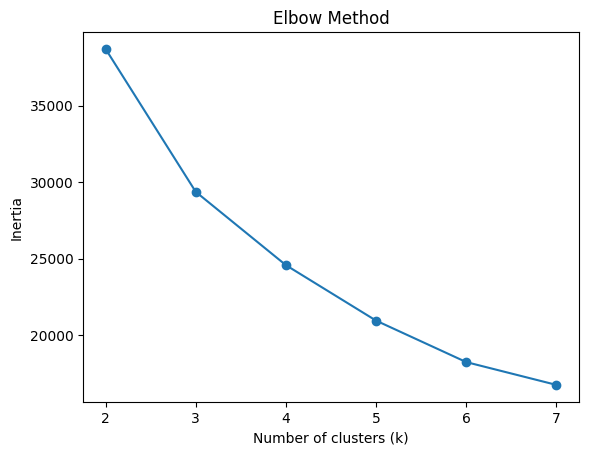

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

K_range = range(2, 8)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.plot(K_range, inertia, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()


In [ ]:
kmeans = KMeans(n_clusters=4, random_state=42)
df["segment"] = kmeans.fit_predict(X_scaled)
df["segment"].value_counts()


,count
segment,
1,4552
0,3326
2,1328
3,921


In [ ]:
segment_profile = df.groupby("segment")[features].mean()
segment_profile


,Total_Trans_Amt,Total_Trans_Ct,Credit_Limit,Avg_Utilization_Ratio,Months_on_book
segment,,,,,
0,3711.840649,64.779916,2753.672880,0.619905,35.809080
1,3255.805141,57.524824,6549.946639,0.110370,36.119069
2,3757.160392,60.704819,26981.025602,0.044925,36.192018
3,13512.123779,107.380022,13692.638436,0.173698,35.036916


In [ ]:
df.groupby("segment")["Attrition_Flag"].value_counts(normalize=True)


segment  Attrition_Flag   
0        Existing Customer    0.915815
         Attrited Customer    0.084185
1        Existing Customer    0.758568
         Attrited Customer    0.241432
2        Existing Customer    0.832078
         Attrited Customer    0.167922
3        Existing Customer    0.972856
         Attrited Customer    0.027144
Name: proportion, dtype: float64

Segment characteristics are identified by comparing the average values of key variables across clusters.
Segment 0 includes customers with low credit limits but high utilization, indicating credit-constrained yet intensive usage.
Segment 1 captures low-engagement customers with relatively low usage despite moderate credit limits, and this group exhibits the highest attrition rate.
Segment 2 represents high-limit but low-utilization customers, suggesting the card is mainly used as a backup.
Segment 3 consists of high-value, highly active customers with the highest transaction amount and frequency.


The results suggest that retention strategies should be tailored by customer segment rather than applied uniformly. Low-engagement customers (Segment 1) exhibit the highest attrition rates and should be prioritized for activation-focused interventions, such as welcome bonus, cashback offers, or limited-time rewards like targeted promotions tied to specific spending categories (e.g., dining, travel, online shopping). High-limit but inactive customers (Segment 2) also show elevated churn risk and may benefit from targeted usage incentives and reactivation campaigns, such as educational communications that highlight card benefits and usage advantages. In contrast, highly active customers (Segment 3) are already stable and may only require maintenance-oriented loyalty programs, while credit-constrained heavy users (Segment 0) may benefit from moderate credit and pricing adjustments.


**Churn Prediction**

While customer segmentation helps identify groups with distinct spending and engagement patterns, it does not directly indicate which individual customers are most likely to churn.

To complement the segmentation analysis, we build a churn prediction model to estimate the probability of attrition at the individual customer level. This allows the bank to prioritize high-risk customers within each segment and operationalize targeted retention strategies.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

In [ ]:
# Target
y = df["Attrition_Flag"].map({
    "Attrited Customer": 1,
    "Existing Customer": 0
})

# Features
features = [
    "Customer_Age",
    "Dependent_count",
    "Months_on_book",
    "Total_Relationship_Count",
    "Months_Inactive_12_mon",
    "Contacts_Count_12_mon",
    "Credit_Limit",
    "Total_Revolving_Bal",
    "Avg_Open_To_Buy",
    "Total_Trans_Amt",
    "Total_Trans_Ct",
    "Avg_Utilization_Ratio"
]

X = df[features]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
logit = LogisticRegression(
    penalty="l2",        # regularization
    C=1.0,               # strength
    solver="liblinear",
    max_iter=1000,
    random_state=42
)

logit.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42, solver='liblinear')

In [28]:
y_pred = logit.predict(X_test_scaled)
y_prob = logit.predict_proba(X_test_scaled)[:, 1]
threshold = 0.5
y_pred_new = (y_prob >= threshold).astype(int)


print(classification_report(y_test, y_pred_new))
print("ROC AUC:", roc_auc_score(y_test, y_prob))

              precision    recall  f1-score   support

           0       0.91      0.97      0.94      2551
           1       0.73      0.48      0.58       488

    accuracy                           0.89      3039
   macro avg       0.82      0.72      0.76      3039
weighted avg       0.88      0.89      0.88      3039

ROC AUC: 0.8953504250984827


ROC AUC = 0.895, indicating that the model can effectively distinguish between attrited and existing customers.

Overall accuracy is 89%, which is solid given the class imbalance in the dataset.

The model performs very well for existing customers, with high precision and recall.

For attrited customers, precision remains reasonable (0.73), meaning most predicted churners are indeed churners.

However, recall for attrited customers is lower (0.48), suggesting that the model is conservative and may miss some churners.

This trade-off is expected and acceptable in many business settings, especially when false positives are costly.

In [ ]:
coef_df = (
    pd.DataFrame({
        "Feature": features,
        "Coefficient": logit.coef_[0]
    })
    .sort_values(by="Coefficient", ascending=False)
)

coef_df

,Feature,Coefficient
9,Total_Trans_Amt,1.318877
5,Contacts_Count_12_mon,0.563172
4,Months_Inactive_12_mon,0.511289
1,Dependent_count,0.234030
0,Customer_Age,-0.000535
8,Avg_Open_To_Buy,-0.029123
11,Avg_Utilization_Ratio,-0.039309
2,Months_on_book,-0.079164
6,Credit_Limit,-0.100311
3,Total_Relationship_Count,-0.766063


The logistic regression coefficients provide insight into which factors are most strongly associated with attrition risk.

Features Associated with Higher Attrition Risk (Positive Coefficients)

Total_Trans_Amt

Contacts_Count_12_mon

Months_Inactive_12_mon

Dependent_count

These features suggest that:

Customers with recent inactivity and frequent service contacts are more likely to churn.

High transaction amount combined with declining engagement may indicate burnout or dissatisfaction rather than loyalty.

Features Associated with Lower Attrition Risk (Negative Coefficients)

Total_Trans_Ct (strongest negative effect)

Total_Revolving_Bal

Total_Relationship_Count

Credit_Limit

Months_on_book

These results indicate that:

Highly engaged customers with frequent transactions are much less likely to churn.

Customers with longer tenure and deeper product relationships tend to be more stable.

Credit availability and revolving balances may reflect stronger ongoing usage.

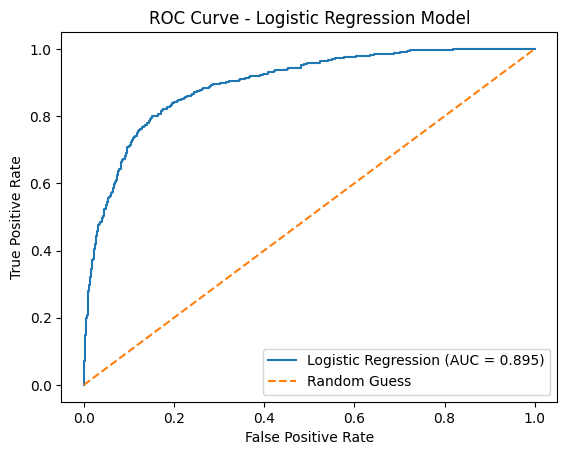

In [27]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_pred_proba = logit.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

auc_score = roc_auc_score(y_test, y_pred_proba)

plt.figure()
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression Model")
plt.legend()
plt.show()

The model confirms that customer engagement and usage intensity are the most important signals for predicting attrition.

Customers who transact frequently and maintain active relationships are significantly less likely to churn.

In contrast, customers showing inactivity patterns or increased customer service interactions represent higher churn risk and should be prioritized for retention efforts.

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report



rf_clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    class_weight="balanced"
)

rf_clf.fit(X_train, y_train)


y_pred = rf_clf.predict(X_test)
y_pred_proba = rf_clf.predict_proba(X_test)[:, 1]
threshold = 0.5
y_pred_adj = (y_pred_proba >= threshold).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_adj))
print("AUC:", roc_auc_score(y_test, y_pred_proba))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_adj))
print("\nClassification Report:\n", classification_report(y_test, y_pred_adj))



Accuracy: 0.9384666008555446
AUC: 0.9764243851655732
Confusion Matrix:
 [[2435  116]
 [  71  417]]

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.95      0.96      2551
           1       0.78      0.85      0.82       488

    accuracy                           0.94      3039
   macro avg       0.88      0.90      0.89      3039
weighted avg       0.94      0.94      0.94      3039



In [19]:
import pandas as pd

feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_clf.feature_importances_
}).sort_values(by="importance", ascending=False)

feature_importance.head(10)


,feature,importance
10,Total_Trans_Ct,0.277865
9,Total_Trans_Amt,0.264510
7,Total_Revolving_Bal,0.136739
11,Avg_Utilization_Ratio,0.073063
3,Total_Relationship_Count,0.062099
8,Avg_Open_To_Buy,0.034870
4,Months_Inactive_12_mon,0.034833
6,Credit_Limit,0.033315
0,Customer_Age,0.029370
5,Contacts_Count_12_mon,0.025697


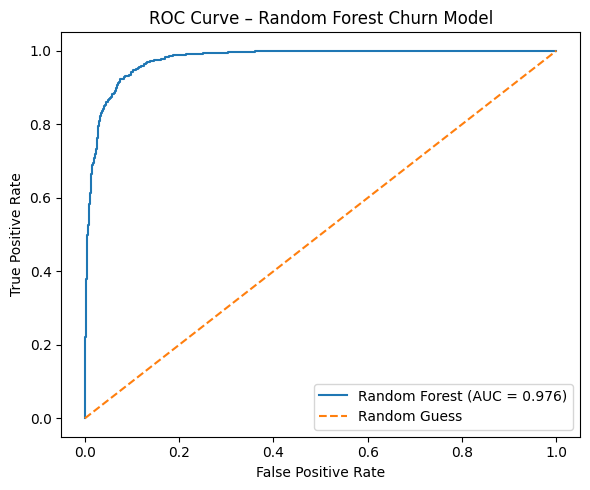

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

y_true = y_test
y_score = y_pred_proba   # P(churn = 1)

fpr, tpr, thresholds = roc_curve(y_true, y_score)
auc_score = roc_auc_score(y_true, y_score)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Random Forest Churn Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [30]:
report_dict = classification_report(
    y_test, y_pred_adj, output_dict=True
)

rf_class_table = pd.DataFrame({
    "Class": ["Non-Churn (0)", "Churn (1)"],
    "Precision": [
        report_dict["0"]["precision"],
        report_dict["1"]["precision"]
    ],
    "Recall": [
        report_dict["0"]["recall"],
        report_dict["1"]["recall"]
    ],
    "F1-score": [
        report_dict["0"]["f1-score"],
        report_dict["1"]["f1-score"]
    ],
    "Support": [
        report_dict["0"]["support"],
        report_dict["1"]["support"]
    ]
})

print("Random Forest Classification Report (Threshold = 0.5)")
print(rf_class_table.round(3))


Random Forest Classification Report (Threshold = 0.5)
           Class  Precision  Recall  F1-score  Support
0  Non-Churn (0)      0.972   0.955     0.963   2551.0
1      Churn (1)      0.782   0.855     0.817    488.0


In [33]:
import pandas as pd
from sklearn.metrics import classification_report

# Logistic Regression classification report
log_report = classification_report(
    y_test,
    y_pred_new,
    output_dict=True
)

log_table = pd.DataFrame({
    "Class": ["Non-Churn (0)", "Churn (1)"],
    "Precision": [
        log_report["0"]["precision"],
        log_report["1"]["precision"]
    ],
    "Recall": [
        log_report["0"]["recall"],
        log_report["1"]["recall"]
    ],
    "F1-score": [
        log_report["0"]["f1-score"],
        log_report["1"]["f1-score"]
    ],
    "Support": [
        log_report["0"]["support"],
        log_report["1"]["support"]
    ]
})

print("Logistic Regression Classification Report (Threshold = 0.5)")
print(log_table.round(3))


Logistic Regression Classification Report (Threshold = 0.5)
           Class  Precision  Recall  F1-score  Support
0  Non-Churn (0)      0.906   0.967     0.936   2551.0
1      Churn (1)      0.734   0.475     0.577    488.0


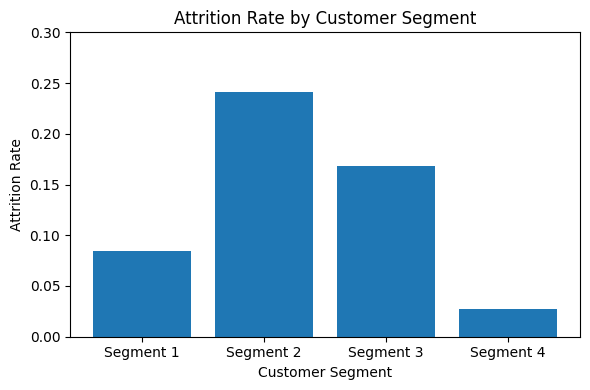

In [53]:
segment_attrition = (
    df.groupby("segment")["Attrition_Flag"]
      .apply(lambda x: (x == "Attrited Customer").mean())
)

plt.figure(figsize=(6,4))
plt.bar(segment_attrition.index, segment_attrition.values)

plt.title("Attrition Rate by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Attrition Rate")

plt.xticks(segment_attrition.index,
           [f"Segment {i+1}" for i in segment_attrition.index])

plt.ylim(0, 0.3)
plt.tight_layout()
plt.show()


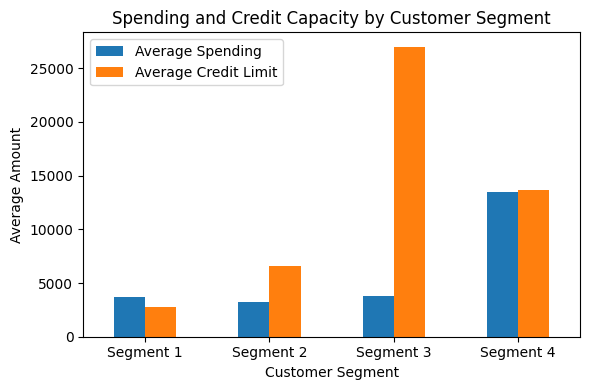

In [50]:
segment_profile_amt = df.groupby("segment")[[
    "Total_Trans_Amt",
    "Credit_Limit"
]].mean()

segment_profile_amt.rename(columns={
    "Total_Trans_Amt": "Average Spending",
    "Credit_Limit": "Average Credit Limit"
}, inplace=True)

ax = segment_profile_amt.plot(
    kind="bar",
    figsize=(6,4)
)

ax.set_title("Spending and Credit Capacity by Customer Segment")
ax.set_xlabel("Customer Segment")
ax.set_ylabel("Average Amount")

ax.set_xticklabels(
    [f"Segment {i+1}" for i in segment_profile_amt.index],
    rotation=0
)

plt.legend()
plt.tight_layout()
plt.show()


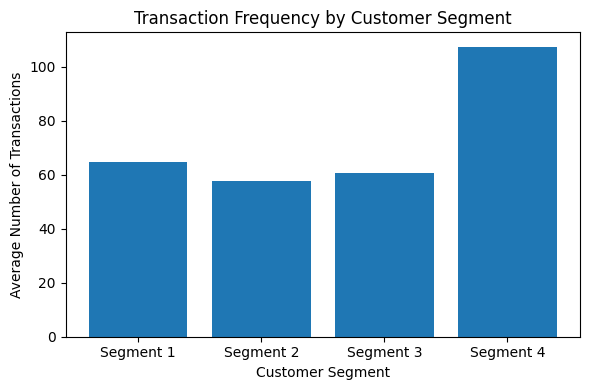

In [51]:
segment_txn = df.groupby("segment")["Total_Trans_Ct"].mean()

plt.figure(figsize=(6,4))
plt.bar(segment_txn.index, segment_txn.values)

plt.title("Transaction Frequency by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Number of Transactions")

plt.xticks(
    segment_txn.index,
    [f"Segment {i+1}" for i in segment_txn.index]
)

plt.tight_layout()
plt.show()


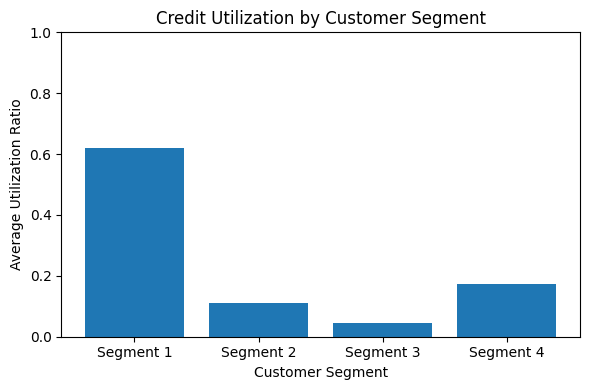

In [56]:
segment_util = df.groupby("segment")["Avg_Utilization_Ratio"].mean()

plt.figure(figsize=(6,4))
plt.bar(segment_util.index, segment_util.values)

plt.title("Credit Utilization by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Utilization Ratio")
plt.ylim(0, 1)

plt.xticks(
    segment_util.index,
    [f"Segment {i+1}" for i in segment_util.index]
)

plt.tight_layout()
plt.show()


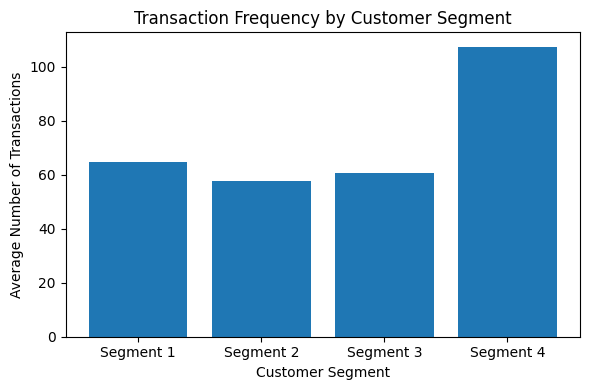

In [58]:
segment_txn = df.groupby("segment")["Total_Trans_Ct"].mean()

plt.figure(figsize=(6,4))
plt.bar(segment_txn.index, segment_txn.values)

plt.title("Transaction Frequency by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Number of Transactions")

plt.xticks(
    segment_txn.index,
    [f"Segment {i+1}" for i in segment_txn.index]
)

plt.tight_layout()
plt.show()


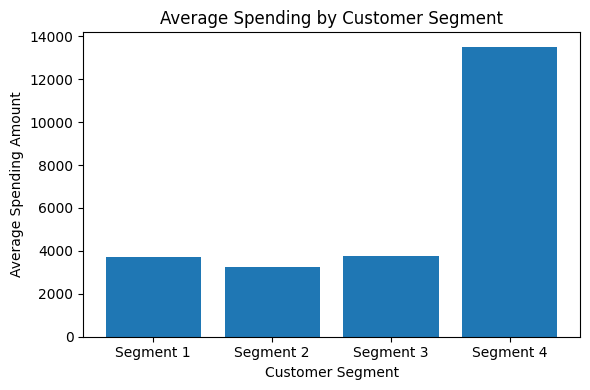

In [59]:
segment_spend = df.groupby("segment")["Total_Trans_Amt"].mean()

plt.figure(figsize=(6,4))
plt.bar(segment_spend.index, segment_spend.values)

plt.title("Average Spending by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Spending Amount")

plt.xticks(
    segment_spend.index,
    [f"Segment {i+1}" for i in segment_spend.index]
)

plt.tight_layout()
plt.show()


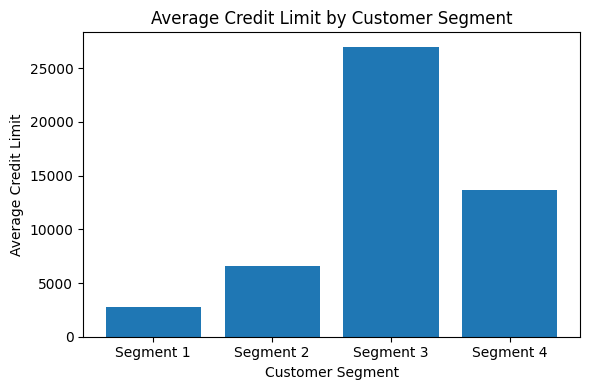

In [60]:
segment_credit = df.groupby("segment")["Credit_Limit"].mean()

plt.figure(figsize=(6,4))
plt.bar(segment_credit.index, segment_credit.values)

plt.title("Average Credit Limit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Credit Limit")

plt.xticks(
    segment_credit.index,
    [f"Segment {i+1}" for i in segment_credit.index]
)

plt.tight_layout()
plt.show()
